In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

In [5]:
# Step 1: Load the data
cars = pd.read_csv("cars.csv")
cars.columns

Index(['car_age', 'km_thousands', 'engine_cc', 'price_lakh'], dtype='object')

In [ ]:
# Step 2: X = features, y = target. Then split 80% train, 20% test
X = cars[['car_age', 'km_thousands', 'engine_cc']]
y = cars["price_lakh"]
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 3 + 4: Choose Linear Regression, create it, and train it
model = LinearRegression()
model.fit(x_train, y_train)

# Step 6 + 7: Residuals and error on the 40 test houses
error = mean_absolute_error(y_test, model.predict(x_test))
print("Average error (MAE):", round(error, 1), "lakh")

Average error (MAE): 2.0 lakh


In [10]:
# Step 5: Predict the price of a NEW house
new_car = pd.DataFrame({"car_age": [10], "km_thousands": [4], "engine_cc": [1300]})
print("Predicted price:", round(model.predict(new_car)[0], 1), "lakh")

Predicted price: 25.0 lakh


In [11]:
new_car = pd.DataFrame({"car_age": [5], "km_thousands": [10], "engine_cc": [600]})
print("Predicted price:", round(model.predict(new_car)[0], 1), "lakh")

Predicted price: 16.5 lakh


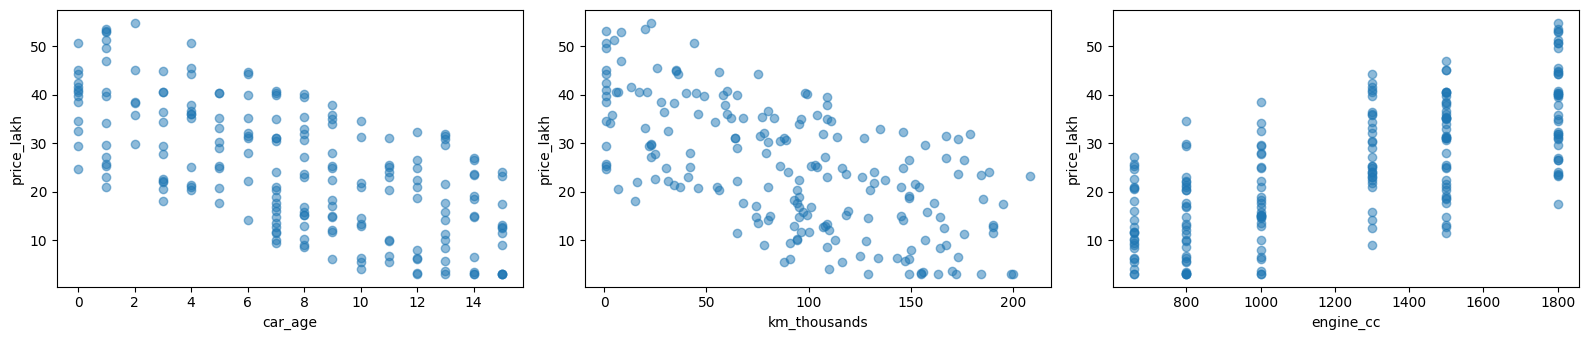

In [14]:
import matplotlib.pyplot as plt
features = ['car_age', 'km_thousands', 'engine_cc']

fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
for ax, col in zip(axes, features):
    ax.scatter(cars[col], cars["price_lakh"], alpha=0.5)
    ax.set_xlabel(col)
    ax.set_ylabel("price_lakh")
plt.tight_layout()
plt.show()

In [15]:
cars.corr()["price_lakh"].round(2)

car_age        -0.65
km_thousands   -0.63
engine_cc       0.70
price_lakh      1.00
Name: price_lakh, dtype: float64

In [16]:
X = cars[features]        # features: what we give the model
y = cars["price_lakh"]    # target: what we want to guess

print("X:", X.shape)    # 200 rows, 4 columns
print("y:", y.shape)    # 200 prices
X.head(3)

X: (200, 3)
y: (200,)


,car_age,km_thousands,engine_cc
0,13,146,1300
1,4,36,1800
2,1,1,1800


In [17]:
# On your own laptop, install once:  pip install scikit-learn
from sklearn.model_selection import train_test_split

# 80% to learn from, 20% to test the model later
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train:", len(X_train), "cars")
print("Test: ", len(X_test), "cars")

Train: 160 cars
Test:  40 cars


In [18]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "KNN": KNeighborsRegressor(n_neighbors=5),
}

for name, m in models.items():
    m.fit(X_train, y_train)                                   # same 3 steps for every model:
    err = mean_absolute_error(y_test, m.predict(X_test))      # create → fit → predict
    print(name, "→ average error:", round(err, 1), "lakh")

Linear Regression → average error: 2.0 lakh
Decision Tree → average error: 3.6 lakh
KNN → average error: 2.9 lakh


In [20]:
line_model = LinearRegression()
line_model.fit(x_train[["engine_cc"]], y_train)

b1 = line_model.coef_[0]
b0 = line_model.intercept_
print("slope (β1):", round(b1, 2))
print("intercept (β0):", round(b0, 2))
print("Rule: price =", round(b0, 1), "+", round(b1, 2), "× engine cc")

slope (β1): 0.02
intercept (β0): -2.75
Rule: price = -2.8 + 0.02 × engine cc


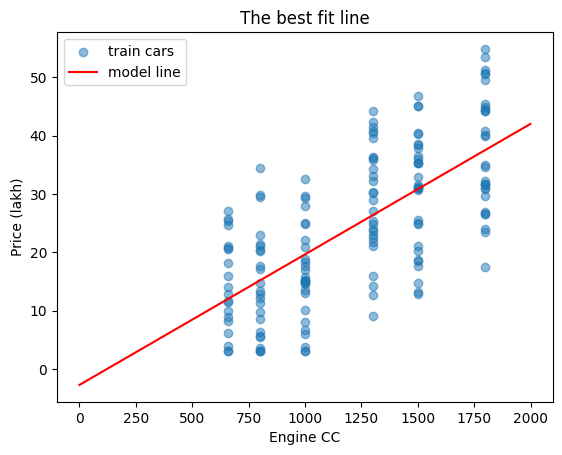

In [27]:
engine = pd.DataFrame({"engine_cc": range(0, 2000)})

plt.scatter(x_train["engine_cc"], y_train, alpha=0.5, label="train cars")
plt.plot(engine["engine_cc"], line_model.predict(engine), color="red", label="model line")
plt.xlabel("Engine CC")
plt.ylabel("Price (lakh)")
plt.title("The best fit line")
plt.legend()
plt.show()

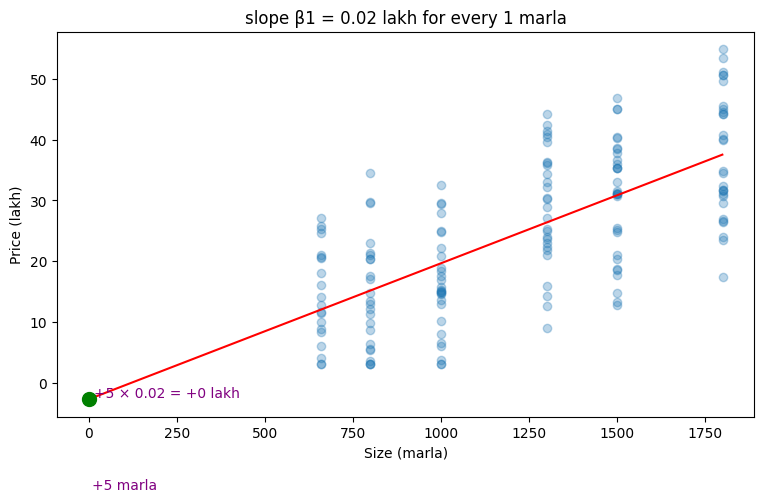

In [42]:
xs = pd.DataFrame({"engine_cc": range(0, 1800)})
plt.figure(figsize=(9, 5))
plt.scatter(x_train["engine_cc"], y_train, alpha=0.3)
plt.plot(xs["engine_cc"], line_model.predict(xs), color="red")

# intercept: the line at size = 0
plt.scatter([0], [b0], color="green", s=100, zorder=3)
# plt.annotate("intercept β0 = " + str(round(b0, 1)), (0, b0), xytext=(0, 2000),
#              arrowprops={"arrowstyle": "->"}, color="green")

# slope: 5 marla right → 5 × β1 lakh up
x1 = 10
y1 = b0 + b1 * x1
plt.plot([x1, x1 + 5], [y1, y1], color="purple", linewidth=3)                 # 5 marla right
plt.plot([x1 + 5, x1 + 5], [y1, y1 + 5 * b1], color="purple", linewidth=3)    # 5 × β1 up
plt.text(x1 + 0.5, y1 - 15, "+5 marla", color="purple")
plt.text(x1 + 5.3, y1 + 2.5 * b1, "+5 × " + str(round(b1, 2)) + " = +" + str(round(5 * b1)) + " lakh", color="purple")
plt.title("slope β1 = " + str(round(b1, 2)) + " lakh for every 1 marla")

plt.xlabel("Size (marla)")
plt.ylabel("Price (lakh)")
plt.show()

Line A → MSE: 5332094697020.0
Line B → MSE: 696299592262.5
Line C (fit) → MSE: 86.7


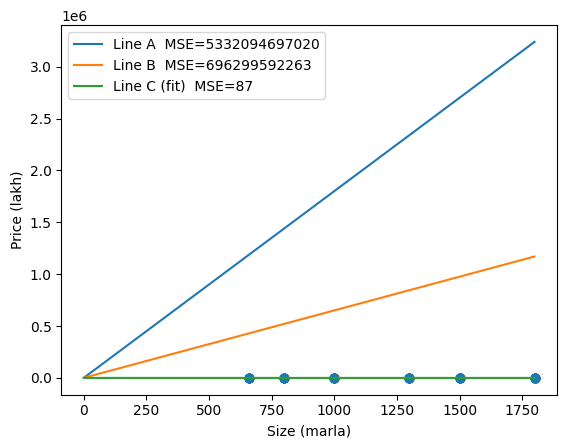

In [44]:
size = x_train["engine_cc"]
price = y_train

lines = {
    "Line A": (1000, 1800),             # (β0, β1) we guessed
    "Line B": (1000, 650),            # (β0, β1) we guessed
    "Line C (fit)": (b0, b1),     # the numbers model.fit found
}

plt.scatter(size, price)
for name, (try_b0, try_b1) in lines.items():
    guess = try_b0 + try_b1 * size                    # the line's price for every house
    mse = ((price - guess) ** 2).mean()       # average of squared residuals
    print(name, "→ MSE:", round(mse, 1))
    plt.plot(xs["engine_cc"], try_b0 + try_b1 * xs["engine_cc"], label=name + "  MSE=" + str(round(mse)))

plt.xlabel("Size (marla)")
plt.ylabel("Price (lakh)")
plt.legend()
plt.show()

In [ ]:
engine_mean = engine.mean()
price_mean = price.mean()


my_b1 = ((engine - engine_mean)*(price - price_mean)).sum() / ((engine-engine_mean)**2).sum()
my_b0 = price_mean - my_b1 * engine_mean
print("By hand    → slope:", round(my_b1, 2), " intercept:", round(my_b0, 2))
print("model.fit  → slope:", round(line_model.coef_[0], 2), " intercept:", round(line_model.intercept_, 2))

By hand    → slope: 0            NaN
1            NaN
2            NaN
3            NaN
4            NaN
            ... 
196          NaN
197          NaN
198          NaN
199          NaN
engine_cc    0.0
Length: 161, dtype: float64  intercept: 0              NaN
1              NaN
2              NaN
3              NaN
4              NaN
             ...  
196            NaN
197            NaN
198            NaN
199            NaN
engine_cc    24.62
Length: 161, dtype: float64
model.fit  → slope: 0.02  intercept: -2.75
